<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 1. Aspectos generales — Modelo 4: Modelo de Cohortes de Retención y Gasto

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Responsable: **Anthony Yucra**.

Construye matrices de retención mensual y gasto promedio por cohorte de adquisición 100 % en **Spark SQL / PySpark nativo** desde `../silver/merge_pyspark`.

Flujo: `../silver/merge_pyspark` ---> `cohorte_mes` (`MIN(Fecha)`) ---> `indice_mes` ---> matriz de retención ---> `../gold/hym_cohortes_retencion`

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

In [2]:
spark = (
    SparkSession.builder
    .appName("HYM_Lab13_04_Cohortes")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.driver.memory", "4g")
    .config("spark.executor.memory", "4g")
    .config("spark.sql.shuffle.partitions", "50")
    .config("spark.memory.fraction", "0.8")
    .getOrCreate()
)

spark.sparkContext.setCheckpointDir("/tmp/spark_checkpoint")
spark

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 2. Rutas de capas

In [3]:
SILVER = "../silver"
GOLD   = "../gold"

import os
os.makedirs(GOLD, exist_ok=True)

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 3. Construcción de cohortes mensuales en Spark SQL

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

- `cohorte_mes`: primer mes de compra del cliente (`TRUNC(MIN(Fecha), 'MM')`).
- `mes_compra`: mes de cada transacción (`TRUNC(Fecha, 'MM')`).
- `indice_mes`: meses transcurridos desde la adquisición (`0, 1, 2, ...`).

In [4]:
%%time
df_silver = spark.read.parquet(f"{SILVER}/merge_pyspark").select("customer_id", "Fecha", "price")
df_silver.filter(F.col("price").isNotNull() & (F.col("price") > 0)).createOrReplaceTempView("tx")

df_cohortes = spark.sql("""
WITH cliente_cohorte AS (
    SELECT customer_id, DATE_TRUNC('MONTH', MIN(Fecha)) AS cohorte_mes
    FROM tx
    GROUP BY customer_id
),
actividad AS (
    SELECT
        t.customer_id,
        c.cohorte_mes,
        DATE_TRUNC('MONTH', t.Fecha) AS mes_compra,
        CAST(ROUND(MONTHS_BETWEEN(DATE_TRUNC('MONTH', t.Fecha), c.cohorte_mes), 0) AS INT) AS indice_mes,
        SUM(t.price) AS gasto_mes
    FROM tx t
    INNER JOIN cliente_cohorte c ON t.customer_id = c.customer_id
    GROUP BY t.customer_id, c.cohorte_mes, DATE_TRUNC('MONTH', t.Fecha)
),
tamanos AS (
    SELECT cohorte_mes, COUNT(DISTINCT customer_id) AS clientes_iniciales
    FROM cliente_cohorte
    GROUP BY cohorte_mes
)
SELECT
    DATE_FORMAT(a.cohorte_mes, 'yyyy-MM') AS cohorte,
    a.indice_mes,
    t.clientes_iniciales,
    COUNT(DISTINCT a.customer_id) AS clientes_activos,
    ROUND(COUNT(DISTINCT a.customer_id) * 100.0 / t.clientes_iniciales, 2) AS tasa_retencion_pct,
    ROUND(SUM(a.gasto_mes), 2) AS ingreso_cohorte_mes,
    ROUND(AVG(a.gasto_mes), 4) AS gasto_medio_activo
FROM actividad a
INNER JOIN tamanos t ON a.cohorte_mes = t.cohorte_mes
GROUP BY a.cohorte_mes, a.indice_mes, t.clientes_iniciales
ORDER BY cohorte, indice_mes
""").checkpoint()

print(f"Celdas de matriz cohorte x mes generadas: {df_cohortes.count():,}")
df_cohortes.filter(F.col("indice_mes").between(0, 6)).show(15, truncate=False)

Celdas de matriz cohorte x mes generadas: 325
+-------+----------+------------------+----------------+------------------+-------------------+------------------+
|cohorte|indice_mes|clientes_iniciales|clientes_activos|tasa_retencion_pct|ingreso_cohorte_mes|gasto_medio_activo|
+-------+----------+------------------+----------------+------------------+-------------------+------------------+
|2018-09|0         |140340            |140340          |100.00            |17755.64           |0.1265            |
|2018-09|1         |140340            |61551           |43.86             |10959.31           |0.1781            |
|2018-09|2         |140340            |59793           |42.61             |10652.63           |0.1782            |
|2018-09|3         |140340            |56736           |40.43             |8950.76            |0.1578            |
|2018-09|4         |140340            |53683           |38.25             |9164.04            |0.1707            |
|2018-09|5         |140340        

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 4. Heatmap de retención (primeros 12 meses) y guardado en Gold

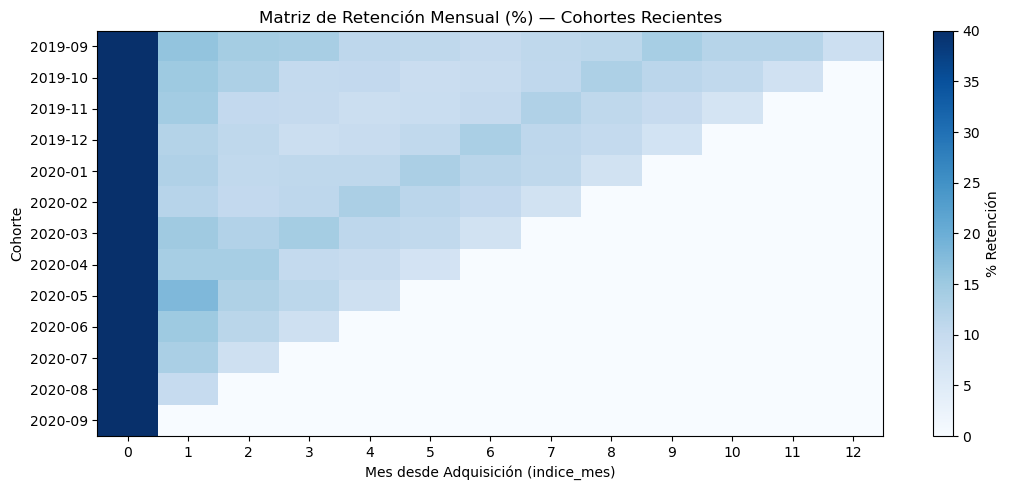

Matriz guardada en ../gold/hym_cohortes_retencion


In [5]:
pdf_mat = (
    df_cohortes
    .filter((F.col("cohorte") >= "2019-09") & (F.col("indice_mes").between(0, 12)))
    .select("cohorte", "indice_mes", "tasa_retencion_pct")
    .toPandas()
    .pivot(index="cohorte", columns="indice_mes", values="tasa_retencion_pct")
    .astype(float)
)

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(pdf_mat.fillna(0).values, aspect="auto", cmap="Blues", vmin=0, vmax=40)
ax.set_yticks(range(len(pdf_mat.index)))
ax.set_yticklabels(pdf_mat.index)
ax.set_xticks(range(len(pdf_mat.columns)))
ax.set_xticklabels(pdf_mat.columns)
ax.set_xlabel("Mes desde Adquisición (indice_mes)")
ax.set_ylabel("Cohorte")
ax.set_title("Matriz de Retención Mensual (%) — Cohortes Recientes")
fig.colorbar(im, ax=ax, label="% Retención")
plt.tight_layout()
plt.show()

df_cohortes.write.mode("overwrite").parquet(f"{GOLD}/hym_cohortes_retencion")
print(f"Matriz guardada en {GOLD}/hym_cohortes_retencion")

In [6]:
spark.stop()